# Pergunta 6 · Educação especial por estado

**Como o peso da educação especial nas matrículas varia entre os estados, e ele acompanha a proporção de pessoas com deficiência e autismo medida pelo IBGE?**

**Recorte:** 27 UFs; matrículas do INEP de **2025** e população do Censo IBGE de **2022**. Deficiência considera pessoas de 2 anos ou mais; autismo, todas as idades. Os percentuais populacionais são resultados preliminares, arredondados a uma casa decimal.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

# Base já tratada: INEP e IBGE reunidos pelo código da UF.
# Os dados estão incluídos no notebook para permitir sua execução independente.
csv_dados = """
codigo_uf,sigla,uf,regiao,matriculas_basica,matriculas_especial,deficiencia_pct,autismo_pct
11,RO,Rondônia,Norte,376264,22898,7.1,1.3
12,AC,Acre,Norte,242727,23739,7.3,1.6
13,AM,Amazonas,Norte,1131739,44033,7.0,1.1
14,RR,Roraima,Norte,186395,8546,5.6,1.2
15,PA,Pará,Norte,2146239,104842,7.3,1.1
16,AP,Amapá,Norte,212026,15602,7.1,1.5
17,TO,Tocantins,Norte,380768,20047,6.9,1.0
21,MA,Maranhão,Nordeste,1821863,86566,8.1,1.1
22,PI,Piauí,Nordeste,823199,49014,9.3,1.2
23,CE,Ceará,Nordeste,2108135,160556,8.9,1.4
24,RN,Rio Grande do Norte,Nordeste,756434,44748,8.8,1.1
25,PB,Paraíba,Nordeste,942549,58813,8.6,1.2
26,PE,Pernambuco,Nordeste,2076655,112445,8.9,1.2
27,AL,Alagoas,Nordeste,831546,43876,9.6,1.1
28,SE,Sergipe,Nordeste,520379,30646,8.6,1.2
29,BA,Bahia,Nordeste,3345058,219850,7.9,1.0
31,MG,Minas Gerais,Sudeste,4220829,227069,7.3,1.1
32,ES,Espírito Santo,Sudeste,867017,59098,7.2,1.3
33,RJ,Rio de Janeiro,Sudeste,3319771,154308,7.4,1.3
35,SP,São Paulo,Sudeste,9600318,373454,6.3,1.2
41,PR,Paraná,Sul,2438428,165666,6.4,1.2
42,SC,Santa Catarina,Sul,1769938,98708,6.0,1.2
43,RS,Rio Grande do Sul,Sul,2189268,143069,7.2,1.1
50,MS,Mato Grosso do Sul,Centro-Oeste,675479,33361,6.5,1.1
51,MT,Mato Grosso,Centro-Oeste,888828,40550,5.7,1.1
52,GO,Goiás,Centro-Oeste,1526256,87001,7.0,1.1
53,DF,Distrito Federal,Centro-Oeste,620272,29654,6.1,1.2
"""

dados = pd.read_csv(StringIO(csv_dados))

## Indicadores

$$
\text{Participação da educação especial (\%)} =
\frac{\text{matrículas da educação especial}}{\text{matrículas da educação básica}}\times 100
$$

O percentual nacional usa a soma das matrículas. A associação com os indicadores do IBGE é medida pela **correlação de Pearson**, com o mesmo peso para cada UF; valores positivos indicam associação linear crescente.

In [2]:
# Conferimos a cobertura e os totais nacionais antes de calcular os indicadores.
assert len(dados) == 27 and dados['codigo_uf'].is_unique
assert not dados.isna().any().any()
assert dados['matriculas_basica'].sum() == 46018380
assert dados['matriculas_especial'].sum() == 2458159

# Participação da educação especial em cada UF e no Brasil.
dados['educacao_especial_pct'] = 100 * dados['matriculas_especial'] / dados['matriculas_basica']
percentual_brasil = 100 * dados['matriculas_especial'].sum() / dados['matriculas_basica'].sum()

# As duas correlações usam as 27 UFs e os valores sem arredondamento adicional.
r_deficiencia = dados['educacao_especial_pct'].corr(dados['deficiencia_pct'])
r_autismo = dados['educacao_especial_pct'].corr(dados['autismo_pct'])

# Verificação complementar da influência do Acre; a análise principal mantém essa UF.
sem_acre = dados[dados['sigla'] != 'AC']
r_autismo_sem_acre = sem_acre['educacao_especial_pct'].corr(sem_acre['autismo_pct'])

# A mesma cor identifica cada região nos três gráficos.
cores = {'Norte': '#087F8C', 'Nordeste': '#C5633A', 'Sudeste': '#386CB0',
         'Sul': '#8B61A8', 'Centro-Oeste': '#9A7820'}
dados['cor'] = dados['regiao'].map(cores)
ranking = dados.sort_values('educacao_especial_pct', ascending=False).reset_index(drop=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

## 1. Participação da educação especial nas matrículas

Cada ponto representa uma UF. A linha tracejada indica o percentual nacional.

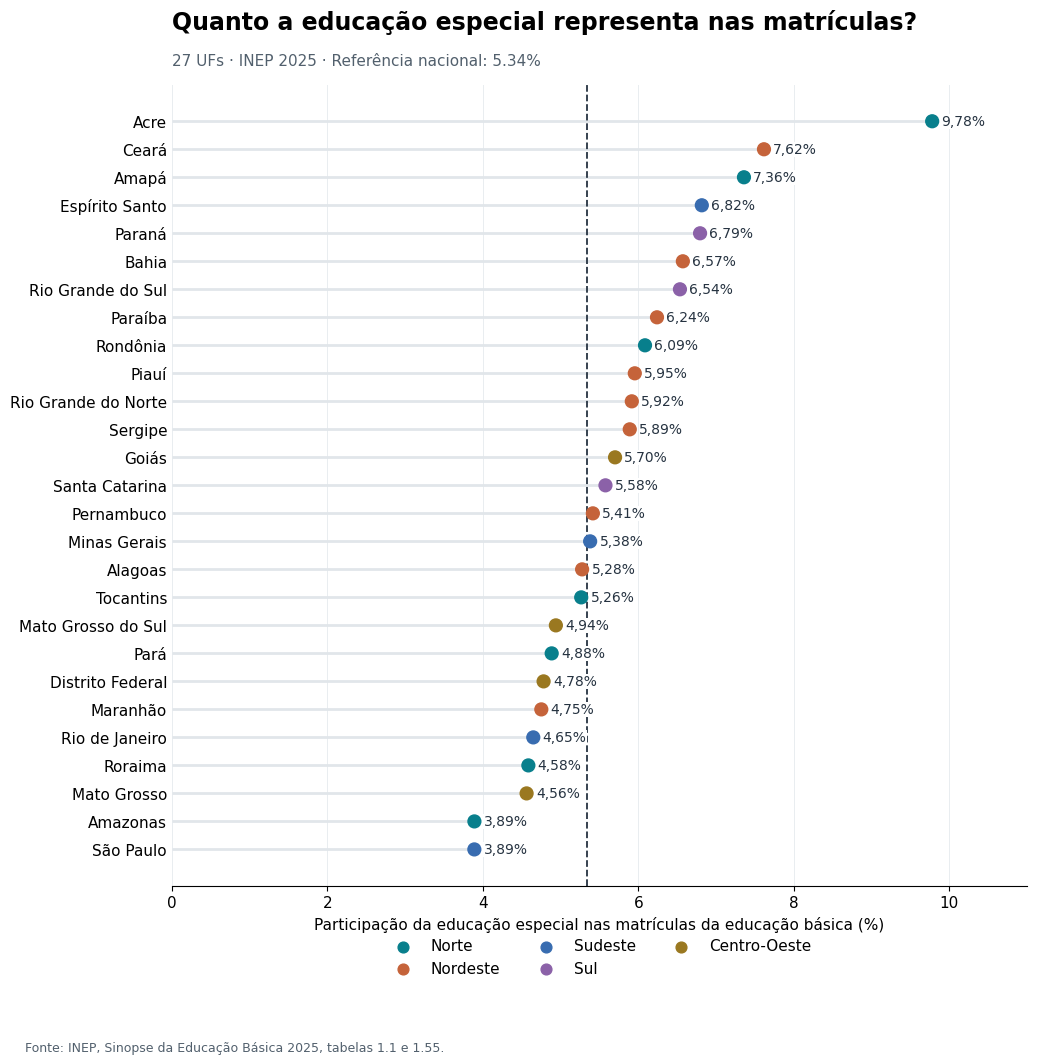

In [3]:
fig_ranking, ax = plt.subplots(figsize=(10.5, 11))

# Ordenação das UFs e referência nacional.
ax.hlines(y=ranking['uf'], xmin=0, xmax=ranking['educacao_especial_pct'],
          color='#E1E6EA', linewidth=2)
ax.scatter(ranking['educacao_especial_pct'], ranking['uf'],
           c=ranking['cor'], s=85, zorder=3)

ax.invert_yaxis()
ax.axvline(percentual_brasil, color='#263341', linestyle='--', linewidth=1.3)

# Valores ao lado dos pontos.
for _, linha in ranking.iterrows():
    rotulo = f"{linha['educacao_especial_pct']:.2f}%".replace('.', ',')
    ax.text(linha['educacao_especial_pct'] + 0.12, linha['uf'], rotulo,
            va='center', fontsize=10, color='#263341',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.4})

ax.set_xlim(0, 11)
ax.set_xlabel('Participação da educação especial nas matrículas da educação básica (%)')
ax.set_title('Quanto a educação especial representa nas matrículas?',
             loc='left', fontsize=17, fontweight='bold', pad=40)
ax.text(0, 1.025, f'27 UFs · INEP 2025 · Referência nacional: {percentual_brasil:.2f}%',
        transform=ax.transAxes, color='#52606D', fontsize=11)
ax.grid(axis='x', color='#E9EDF0', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)

# Legenda por região.
for regiao, cor in cores.items():
    ax.scatter([], [], color=cor, s=60, label=regiao)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig_ranking.text(0.03, 0.018, 'Fonte: INEP, Sinopse da Educação Básica 2025, tabelas 1.1 e 1.55.',
                 color='#52606D', fontsize=9)
fig_ranking.tight_layout(rect=[0, 0.06, 1, 0.98])
plt.show()

## 2. Associação com a proporção de pessoas com deficiência

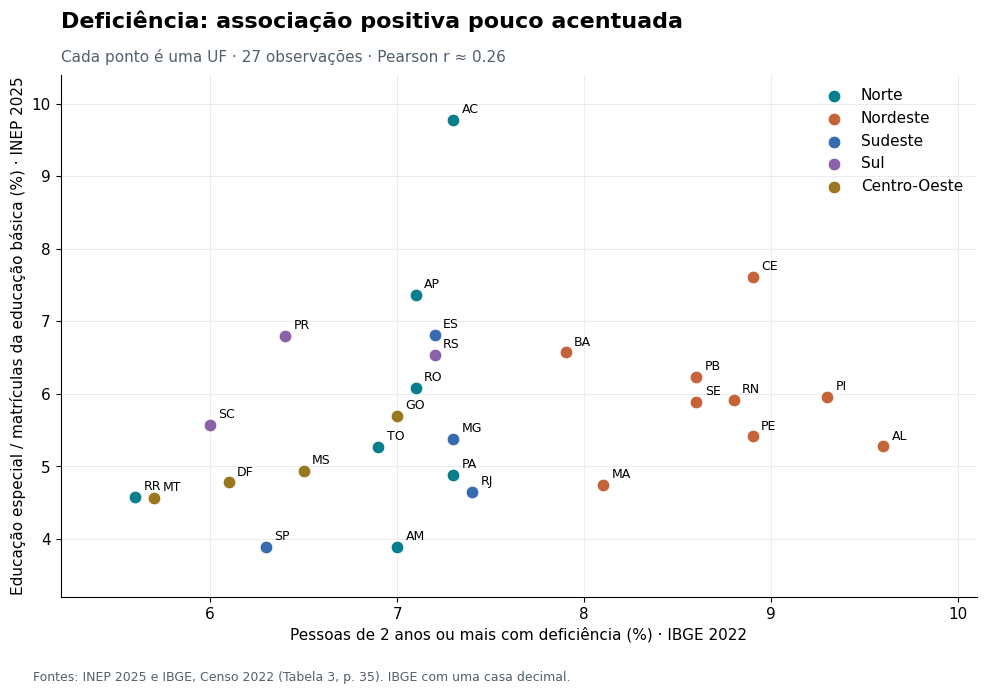

In [4]:
fig_deficiencia, ax = plt.subplots(figsize=(10, 7.2))

# Cada ponto é uma UF; as cores identificam as regiões.
for regiao, cor in cores.items():
    grupo = dados[dados['regiao'] == regiao]
    ax.scatter(grupo['deficiencia_pct'], grupo['educacao_especial_pct'],
               color=cor, s=85, edgecolor='white', linewidth=0.7, label=regiao)

# Identificação das UFs pelas siglas.
for _, linha in dados.iterrows():
    ax.annotate(linha['sigla'],
                (linha['deficiencia_pct'], linha['educacao_especial_pct']),
                xytext=(6, 5), textcoords='offset points', fontsize=9)

ax.set_xlim(5.2, 10.1)
ax.set_ylim(3.2, 10.4)
ax.set_xlabel('Pessoas de 2 anos ou mais com deficiência (%) · IBGE 2022')
ax.set_ylabel('Educação especial / matrículas da educação básica (%) · INEP 2025')
ax.set_title('Deficiência: associação positiva pouco acentuada',
             loc='left', fontsize=16, fontweight='bold', pad=34)
ax.text(0, 1.025, f'Cada ponto é uma UF · 27 observações · Pearson r ≈ {r_deficiencia:.2f}',
        transform=ax.transAxes, fontsize=11, color='#52606D')
ax.grid(color='#E9EDF0', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper right', frameon=False)
fig_deficiencia.text(0.04, 0.025, 'Fontes: INEP 2025 e IBGE, Censo 2022 (Tabela 3, p. 35). IBGE com uma casa decimal.',
                     fontsize=9, color='#52606D')
fig_deficiencia.tight_layout(rect=[0, 0.055, 1, 0.98])
plt.show()

## 3. Associação com a proporção de pessoas com diagnóstico de autismo

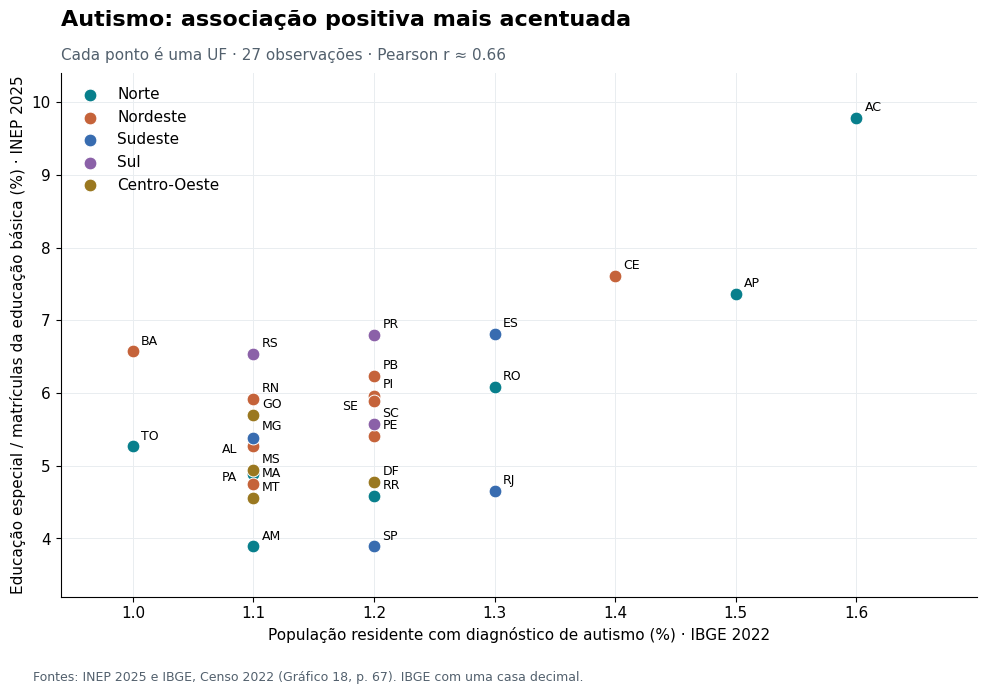

In [5]:
fig_autismo, ax = plt.subplots(figsize=(10, 7.2))

for regiao, cor in cores.items():
    grupo = dados[dados['regiao'] == regiao]
    ax.scatter(grupo['autismo_pct'], grupo['educacao_especial_pct'],
               color=cor, s=85, edgecolor='white', linewidth=0.7, label=regiao)

# Ajustamos apenas os rótulos próximos, preservando a posição dos dados.
ajustes = {'AL': (-23, -5), 'PA': (-23, -5), 'SE': (-23, -6),
           'PI': (6, 6), 'MG': (6, 6), 'MS': (6, 5)}
for _, linha in dados.iterrows():
    deslocamento = ajustes.get(linha['sigla'], (6, 5))
    ax.annotate(linha['sigla'],
                (linha['autismo_pct'], linha['educacao_especial_pct']),
                xytext=deslocamento, textcoords='offset points', fontsize=9)

ax.set_xlim(0.94, 1.70)
ax.set_ylim(3.2, 10.4)
ax.set_xticks([1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6])
ax.set_xlabel('População residente com diagnóstico de autismo (%) · IBGE 2022')
ax.set_ylabel('Educação especial / matrículas da educação básica (%) · INEP 2025')
ax.set_title('Autismo: associação positiva mais acentuada',
             loc='left', fontsize=16, fontweight='bold', pad=34)
ax.text(0, 1.025, f'Cada ponto é uma UF · 27 observações · Pearson r ≈ {r_autismo:.2f}',
        transform=ax.transAxes, fontsize=11, color='#52606D')
ax.grid(color='#E9EDF0', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False)
fig_autismo.text(0.04, 0.025, 'Fontes: INEP 2025 e IBGE, Censo 2022 (Gráfico 18, p. 67). IBGE com uma casa decimal.',
                 fontsize=9, color='#52606D')
fig_autismo.tight_layout(rect=[0, 0.055, 1, 0.98])
plt.show()

## Conclusão

- A participação da educação especial varia de **3,89% em São Paulo a 9,78% no Acre**, com **5,34% no Brasil**. Amazonas também apresenta 3,89% após arredondamento.
- A associação linear é positiva e pequena para **deficiência (r ≈ 0,26)**, e mais acentuada para **diagnóstico de autismo (r ≈ 0,66)**.
- O Acre influencia a segunda relação: sem essa UF, **r ≈ 0,46**. O indicador de autismo acompanha parcialmente a variação entre UFs, mas não descreve toda a diferença nas matrículas.

**Limites:** os anos e os públicos das bases são diferentes; matrículas não são pessoas únicas. Os coeficientes são aproximados devido ao arredondamento do IBGE. A comparação não mede cobertura ou qualidade do atendimento, e associação não demonstra causalidade.

**Fontes:** [INEP — Sinopse da Educação Básica 2025](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica), tabelas 1.1 e 1.55, totais por UF; [IBGE — Censo Demográfico 2022](https://www.ibge.gov.br/biblioteca/visualizacao/livros/liv102178.pdf), *Pessoas com deficiência e pessoas diagnosticadas com transtorno do espectro autista*, Tabela 3 (p. 35) e Gráfico 18 (p. 67). [Cópia da publicação consultada](https://dados.dataverso.org/wp-content/uploads/sites/9/tainacan-items/122/1230/liv102178.pdf).